In [1]:
import os

import akshare_proxy_patch
from dotenv import load_dotenv

load_dotenv()
auth_token = os.getenv("AKSHARE_PROXY_AUTH_TOKEN")

akshare_proxy_patch.install_patch(
    "101.201.173.125",
    auth_token=auth_token,
    retry=30,
    hook_domains=["push2his.eastmoney.com"],
    fast=True,
)

In [2]:
from datetime import date

import akshare as ak
import pandas as pd

In [3]:
# Customization
symbol = "515180"
moving_average_window = 120
deviation_threshold = 0.07

In [4]:
df = ak.fund_etf_hist_em(
    symbol=symbol,
    period="daily",
    start_date="19700101",
    end_date=date.today().strftime("%Y%m%d"),
    adjust="qfq",
)

df["日期"] = pd.to_datetime(df["日期"])
df = df.sort_values("日期").reset_index(drop=True)

df["MA"] = (
    df["收盘"]
    .rolling(window=moving_average_window, min_periods=moving_average_window)
    .mean()
)
df["偏离度"] = df["收盘"] / df["MA"] - 1
df_valid = df.dropna(subset=["MA"]).copy()

buy_signals = df_valid[df_valid["偏离度"] < -deviation_threshold].copy()

In [5]:
print(f"标的: {symbol}")
print(f"均线窗口: {moving_average_window} 日 | 偏离阈值: {deviation_threshold:.0%}")
print(f"历史区间: {df_valid['日期'].min().date()} ~ {df_valid['日期'].max().date()}")
print(f"触发买点次数: {len(buy_signals)}")
print("-" * 60)

if len(buy_signals) > 0:
    output = buy_signals[["日期", "收盘", "MA", "偏离度"]].copy()
    output["日期"] = output["日期"].dt.strftime("%Y-%m-%d")
    output["收盘"] = output["收盘"].round(4)
    output["MA"] = output["MA"].round(4)
    output["偏离度"] = output["偏离度"].map(lambda x: f"{x:.2%}")
    output.columns = ["日期", "收盘", "MA", "偏离度"]
    print(output.to_string(index=False))
else:
    print("在指定区间内未出现符合条件的买点。")

标的: 515180
均线窗口: 120 日 | 偏离阈值: 7%
历史区间: 2020-06-19 ~ 2026-10-26
触发买点次数: 25
------------------------------------------------------------
        日期    收盘     MA     偏离度
2022-03-15 0.863 0.9811 -12.04%
2022-03-16 0.886 0.9793  -9.53%
2022-03-17 0.906 0.9775  -7.31%
2022-04-25 0.903 0.9721  -7.11%
2022-04-26 0.882 0.9718  -9.24%
2022-04-27 0.895 0.9715  -7.88%
2022-10-31 0.897 0.9770  -8.19%
2022-11-01 0.908 0.9769  -7.05%
2024-01-22 0.994 1.0703  -7.13%
2024-09-06 1.075 1.1622  -7.50%
2024-09-09 1.053 1.1615  -9.34%
2024-09-10 1.055 1.1608  -9.12%
2024-09-11 1.031 1.1600 -11.12%
2024-09-12 1.034 1.1592 -10.80%
2024-09-13 1.030 1.1583 -11.08%
2024-09-18 1.043 1.1575  -9.89%
2024-09-19 1.049 1.1568  -9.32%
2024-09-20 1.046 1.1561  -9.52%
2024-09-23 1.059 1.1555  -8.35%
2026-06-25 1.257 1.3564  -7.33%
2026-06-26 1.234 1.3559  -8.99%
2026-06-29 1.238 1.3553  -8.66%
2026-06-30 1.216 1.3546 -10.23%
2026-07-01 1.239 1.3540  -8.49%
2026-07-02 1.250 1.3535  -7.65%


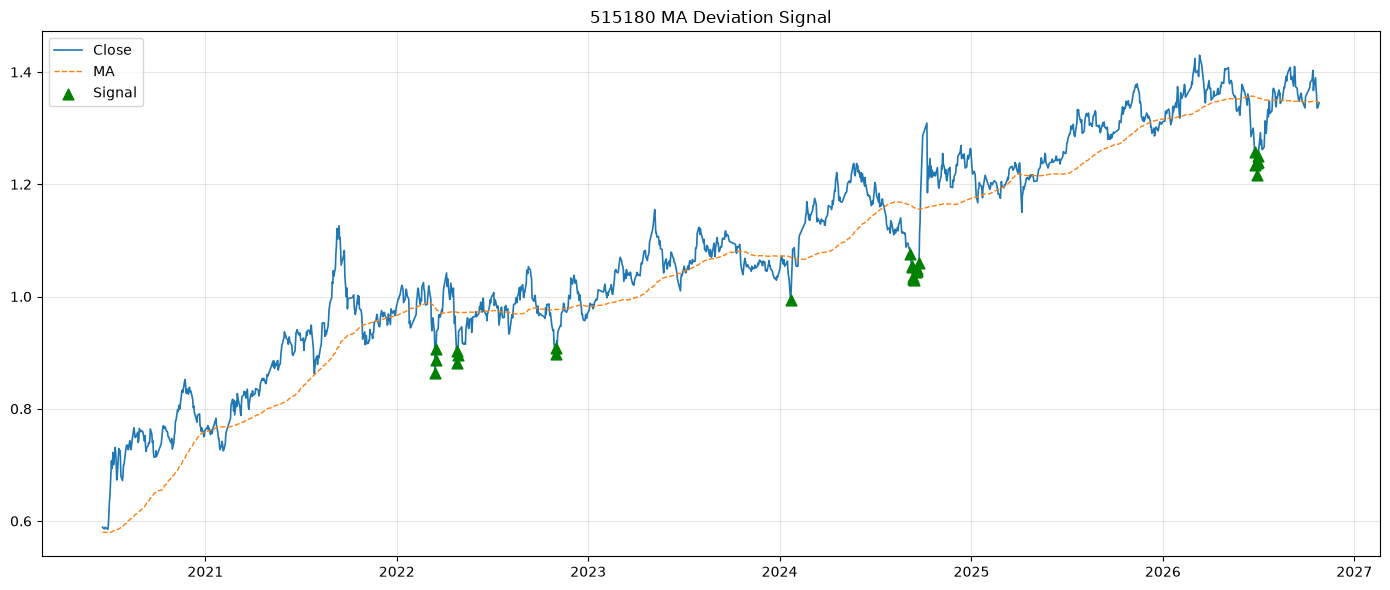

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_valid["日期"], df_valid["收盘"], label="Close", linewidth=1.2)
ax.plot(df_valid["日期"], df_valid["MA"], label="MA", linewidth=1.0, linestyle="--")
ax.scatter(
    buy_signals["日期"],
    buy_signals["收盘"],
    color="green",
    marker="^",
    s=60,
    label="Signal",
    zorder=5,
)
ax.set_title(f"{symbol} MA Deviation Signal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()